In [1]:
import os
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import matplotlib.image as mpimg
import seaborn as sns
import pymol2
from Bio.PDB.MMCIFParser import MMCIFParser
import copy
from Bio.PDB.SASA import ShrakeRupley
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# representative high vs low structures for one TF pair: RUNX1-LEF1 (motif combination 14_157); RUNX1-ETS1 is in notebook 4b
# domain-only BSA comes from scripts/domain_bsa.py (curated UniProt/Pfam domains, see notebook 7)
OUT = "../af3_screen_n100_rho0.6/outputs_inference"
GROUPS = ["RUNX1_LEF1_14_157"]
PAIR = "_".join(GROUPS[0].split("_")[:2])
# how the two example models are picked:
#   "quantile"        high model at the 90th, low model at the 10th percentile of domain BSA
#   "max_paired_diff" the high and low model of the one background with the largest high - low domain BSA
#                     (the most extreme matched pair, not a typical one - see the distribution figure below)
#   "median_paired_diff" the high and low model of the background whose high - low domain BSA is closest
#                     to the median difference (a typical matched pair)
REP_MODE = "quantile"
Q_HIGH, Q_LOW = 0.9, 0.1
# residues outside the annotated domains (mostly disordered, low-confidence placement), drawn as tubes
# in a lighter tint of each TF's colour:
#   "none"     structured domains only
#   "linkers"  only the linker between two annotated domains of the same TF (e.g. ETS1 PNT - ETS)
#   "all"      everything (figures are then saved as *_full_length*.pdf)
SHOW_IDR = "none"
TAG = "full_length" if SHOW_IDR == "all" else "domains"
# regions used instead of the curated UniProt/Pfam domains, {TF: [(start, end, label), ...]}; {} = curated domains.
# The domain-only BSA is then recomputed here for this TF pair (cached in results/cache/).
DOMAIN_OVERRIDE = {}
# camera of the interface-mesh figure:
#   "interface"  side view of the TF1-TF2 interface of the high model, DNA on top
#   "dna:<deg>"  DNA of the high model horizontal, rotated by <deg> about the DNA axis
CAMERA = "interface"
IDR_NOTE = {"none": "", "linkers": "linker between a TF's domains: lighter tint",
            "all": "residues outside the annotated domains: lighter tint"}[SHOW_IDR]

# structure colours in the style of Baker-lab figures (teal / yellow complex partners, grey context;
# e.g. Vazquez Torres et al. Nature 2023, Cao et al. Nature 2022)
COL = {"TF1": "#1f9e96", "TF2": "#f2c14e", "DNA": "#d0d0d0", "IFACE": "#e4572e",
       "MOTIF1": "#0f766e", "MOTIF2": "#b7791f",  # each TF's motif on the DNA: darker shade of that TF's colour
       "IDR1": "#a6dbd6", "IDR2": "#fae6b0"}  # residues outside the annotated domains (only if SHOW_IDR)
COL_NAME = {"TF1": "teal", "TF2": "yellow", "DNA": "light grey", "IFACE": "orange-red",
            "MOTIF1": "dark teal", "MOTIF2": "dark amber"}

def yy_pymol_colours(cmd):
    for k, hexcol in COL.items():
        cmd.set_color(f"yy_{k}", [int(hexcol[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def yy_pymol_style(cmd):
    """flat, outlined look (white background, no shadows, black silhouettes)"""
    cmd.bg_color("white")
    cmd.set("ray_opaque_background", 0)
    cmd.set("ray_shadows", 0)
    cmd.set("ray_trace_mode", 1)
    cmd.set("ray_trace_color", "black")
    cmd.set("antialias", 2)
    cmd.set("ambient", 0.4)
    cmd.set("specular", 0.1)
    cmd.set("cartoon_ring_mode", 3)
    cmd.set("cartoon_ring_finder", 1)
    cmd.set("cartoon_discrete_colors", 1)
    cmd.set("stick_radius", 0.22)

full = pd.read_csv("../results/tables/bsa_n100_rho0.6_high_vs_low.csv")
bsa = full[full["group"].isin(GROUPS)].merge(pd.read_csv("../results/cache/domain_bsa_checkpoint.csv"), on="name")
bsa.groupby(["group", "class"])[["BSA", "BSA_domain", "domains_touch"]].agg(["median", "mean"]).round(2)

BSA         BSA_domain         domains_touch     
                         median    mean     median    mean        median mean
group             class                                                      
RUNX1_LEF1_14_157 high   972.17  962.57     125.37  125.39           1.0  1.0
                  low    744.55  717.48       0.00    0.00           0.0  0.0

In [3]:
# structured domains from UniProt/Pfam (data/tf_domains_structured.csv; residue numbers = model numbering)
domains = pd.read_csv("../data/tf_domains_structured.csv")
tfs = sorted({tf for g in GROUPS for tf in g.split("_")[:2]})

def yy_keep(model, keep):
    """Copy of model with only {chain_id: set(resnums)} (as scripts/domain_bsa.py)."""
    m = copy.deepcopy(model)
    for ch in list(m):
        if ch.id not in keep:
            m.detach_child(ch.id)
            continue
        for res in list(ch):
            if res.id[1] not in keep[ch.id]:
                ch.detach_child(res.id)
    return m

def yy_sasa(model):
    ShrakeRupley(probe_radius=1.4, n_points=100).compute(model, level="A")
    return sum(a.sasa for a in model.get_atoms())

def yy_region_bsa(name, res_a, res_b):
    """TF1-TF2 BSA restricted to the given residue sets (same definition as scripts/domain_bsa.py)."""
    model = MMCIFParser(QUIET=True).get_structure(name, f"{OUT}/{name}_model.cif")[0]
    both = yy_keep(model, {"A": res_a, "B": res_b})
    atoms_b = np.array([a.coord for a in both["B"].get_atoms() if a.element != "H"])
    touch = any(np.min(np.linalg.norm(atoms_b - a.coord, axis=1)) <= 4.0 for a in both["A"].get_atoms() if a.element != "H")
    bsa_dom = 0.5 * (yy_sasa(yy_keep(both, {"A": res_a})) + yy_sasa(yy_keep(both, {"B": res_b})) - yy_sasa(both))
    return max(bsa_dom, 0.0), touch

if DOMAIN_OVERRIDE:
    custom = pd.DataFrame([{"TF": tf, "accession": "custom", "domain": lab, "start": s, "end": e}
                           for tf, segs in DOMAIN_OVERRIDE.items() for s, e, lab in segs])
    domains = pd.concat([domains[~domains["TF"].isin(DOMAIN_OVERRIDE)], custom], ignore_index=True)
    res = {tf: set().union(*(range(s, e + 1) for s, e in zip(g["start"], g["end"]))) for tf, g in domains.groupby("TF")}
    for group in GROUPS:
        tf1, tf2 = group.split("_")[:2]
        key = "__".join(f"{tf}_" + "+".join(f"{s}-{e}" for s, e, _ in DOMAIN_OVERRIDE[tf]) for tf in (tf1, tf2) if tf in DOMAIN_OVERRIDE)
        cache = f"../results/cache/domain_bsa_{group}__{key}.csv"
        if not os.path.exists(cache):
            names = bsa.loc[bsa["group"] == group, "name"]
            vals = [yy_region_bsa(n, res[tf1], res[tf2]) for n in names]
            pd.DataFrame({"name": names.values, "BSA_domain": [v[0] for v in vals],
                          "domains_touch": [v[1] for v in vals]}).to_csv(cache, index=False)
        new = pd.read_csv(cache).set_index("name")
        sel = bsa["group"] == group
        bsa.loc[sel, "BSA_domain"] = bsa.loc[sel, "name"].map(new["BSA_domain"])
        bsa.loc[sel, "domains_touch"] = bsa.loc[sel, "name"].map(new["domains_touch"])
    display(bsa.groupby(["group", "class"])[["BSA", "BSA_domain", "domains_touch"]].agg(["median", "mean"]).round(2))
domains[domains["TF"].isin(tfs)]

,TF,accession,domain,start,end
25,LEF1,Q9UJU2,HMG (high mobility group) box / HMG box,299,367
36,RUNX1,Q01196,Runt / Runt domain,50,179


In [4]:
# each TF's motif in the modelled DNA (chain C = 'sequence' 5'->3', chain D = its reverse complement)
seqs = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv", dtype={"motif_combination": str})
seqs["name"] = (seqs["TF1"] + "_" + seqs["TF2"] + "_" + seqs["motif_combination"] + "_" + seqs["class"]
                + "_bg" + seqs["background_idx"].astype(str))
seqs = seqs.set_index("name")

def yy_motif_pos(name):
    """{'MOTIF1': (start, end), 'MOTIF2': (start, end)}: 1-based position of each TF's motif on chain C
    (motif searched on either strand; None if it is not found as an exact match)."""
    r = seqs.loc[name]
    rc = lambda x: x[::-1].translate(str.maketrans("ACGT", "TGCA"))
    pos = {}
    for k, motif in [("MOTIF1", r["motif1"]), ("MOTIF2", r["motif2"])]:
        i = max(r["sequence"].find(motif), r["sequence"].find(rc(motif)))
        pos[k] = (i + 1, i + len(motif)) if i >= 0 else None
    return pos

def yy_colour_motifs(cmd, obj, name):
    """colour the nucleotides of each TF's motif (both strands) in a darker shade of that TF's colour"""
    n = len(seqs.loc[name, "sequence"])
    for k, se in yy_motif_pos(name).items():
        if se is not None:
            cmd.color(f"yy_{k}", f"{obj} and ((chain C and resi {se[0]}-{se[1]}) or (chain D and resi {n + 1 - se[1]}-{n + 1 - se[0]}))")

def yy_draw_sequence(ax, name, y=-0.03, dx=0.03, fontsize=10):
    """write the modelled DNA (chain C, 5'->3') under a panel, with each TF's motif in its motif colour"""
    seq, pos = seqs.loc[name, "sequence"], yy_motif_pos(name)
    x0 = 0.5 - dx * (len(seq) - 1) / 2
    ax.text(x0 - 1.2 * dx, y, "5'", transform=ax.transAxes, ha="right", va="top", fontsize=fontsize - 2, color="0.5")
    ax.text(x0 + dx * len(seq) + 0.2 * dx, y, "3'", transform=ax.transAxes, ha="left", va="top", fontsize=fontsize - 2, color="0.5")
    for i, nt in enumerate(seq, start=1):
        key = next((k for k, se in pos.items() if se is not None and se[0] <= i <= se[1]), None)
        ax.text(x0 + dx * (i - 1), y, nt, transform=ax.transAxes, ha="center", va="top", fontsize=fontsize,
                family="DejaVu Sans Mono", color=COL[key] if key else "0.6", fontweight="bold" if key else "normal")

def yy_resi(tf):
    """PyMOL resi selection for a TF's structured domains, e.g. '50-179' or '51-136+335-415'."""
    d = domains[domains["TF"] == tf]
    return "+".join(f"{s}-{e}" for s, e in zip(d["start"], d["end"]))

def yy_idr_resi(tf):
    """PyMOL resi selection of the non-domain residues to draw for a TF (see SHOW_IDR); None if nothing."""
    d = domains[domains["TF"] == tf].sort_values("start")
    if SHOW_IDR == "all":
        return f"not resi {yy_resi(tf)}"
    if SHOW_IDR == "linkers" and len(d) > 1:
        return "resi " + "+".join(f"{e + 1}-{s - 1}" for e, s in zip(d["end"].iloc[:-1], d["start"].iloc[1:]))
    return None

def yy_show_idr(cmd, obj, tf1, tf2):
    """draw the residues chosen by SHOW_IDR as tubes in a lighter tint of the TF's colour.
    Returns the PyMOL selection that was shown ('none' if nothing)."""
    shown = []
    for chain, tf, col in [("A", tf1, "yy_IDR1"), ("B", tf2, "yy_IDR2")]:
        resi = yy_idr_resi(tf)
        if resi is None:
            continue
        sele = f"({obj} and chain {chain} and {resi})"
        cmd.show("cartoon", sele)
        # as tubes: thin loops would be swallowed by the black outlines of the flat render style
        cmd.cartoon("tube", sele)
        cmd.set("cartoon_tube_radius", 0.9)
        cmd.color(col, sele)
        shown.append(sele)
    return " or ".join(shown) if shown else "none"

def yy_domain_label(tf):
    d = domains[domains["TF"] == tf]
    return ", ".join(f"{n.split(' / ')[0]} {s}-{e}" for n, s, e in zip(d["domain"], d["start"], d["end"]))

# representatives (see REP_MODE above)
reps = {}
for group in GROUPS:
    sub = bsa[bsa["group"] == group]
    if REP_MODE in ("max_paired_diff", "median_paired_diff"):
        wide = sub.pivot(index="background_idx", columns="class", values="BSA_domain")
        diff = wide["high"] - wide["low"]
        bg = diff.idxmax() if REP_MODE == "max_paired_diff" else (diff - diff.median()).abs().idxmin()
        for cls in ["high", "low"]:
            reps[(group, cls)] = sub.loc[(sub["class"] == cls) & (sub["background_idx"] == bg), "name"].iloc[0]
    else:
        for cls, q in [("high", Q_HIGH), ("low", Q_LOW)]:
            c = sub[sub["class"] == cls]
            reps[(group, cls)] = c.loc[(c["BSA_domain"] - c["BSA_domain"].quantile(q)).abs().idxmin(), "name"]
bsa[bsa["name"].isin(reps.values())][["group", "class", "name", "BSA_domain", "BSA", "iptm_AB"]]

,group,class,name,BSA_domain,BSA,iptm_AB
27,RUNX1_LEF1_14_157,high,RUNX1_LEF1_14_157_high_bg26,1.377585e+02,988.502750,0.36
158,RUNX1_LEF1_14_157,low,RUNX1_LEF1_14_157_low_bg45,9.094947e-13,714.240191,0.35


In [5]:
# PyMOL: structured domains only (cartoon, TF1 teal / TF2 yellow), DNA light grey,
# domain-domain interface residues (<= 4.5 A) as sticks (N blue, O red).
# low is superposed on high via DNA phosphates and both are oriented on the DNA, so the two panels share one view
def yy_render_pair(group, width=1400, height=1100):
    tf1, tf2 = group.split("_")[:2]
    p = pymol2.PyMOL()
    p.start()
    cmd = p.cmd
    for cls in ["high", "low"]:
        cmd.load(f"{OUT}/{reps[(group, cls)]}_model.cif", cls)
    cmd.pair_fit("low and chain C+D and name P", "high and chain C+D and name P")
    cmd.hide("everything")
    yy_pymol_colours(cmd)
    yy_pymol_style(cmd)
    for cls in ["high", "low"]:
        dom_a, dom_b = f"({cls} and chain A and resi {yy_resi(tf1)})", f"({cls} and chain B and resi {yy_resi(tf2)})"
        cmd.show("cartoon", f"{dom_a} or {dom_b} or ({cls} and chain C+D)")
        cmd.color("yy_TF1", dom_a)
        cmd.color("yy_TF2", dom_b)
        cmd.color("yy_DNA", f"{cls} and chain C+D")
        yy_show_idr(cmd, cls, tf1, tf2)
        cmd.select("iface", f"byres ({dom_a} within 4.5 of {dom_b}) or byres ({dom_b} within 4.5 of {dom_a})")
        cmd.show("sticks", "iface and not name N+C+O")
        cmd.color("blue", "iface and elem N")
        cmd.color("red", "iface and elem O")
    cmd.orient("high and chain C+D")
    cmd.zoom("rep cartoon or rep sticks", buffer=2, complete=1)
    for cls in ["high", "low"]:
        cmd.disable("all")
        cmd.enable(cls)
        cmd.png(f"../results/figures/representative_structures/{reps[(group, cls)]}_{TAG}.png",
                width=width, height=height, dpi=150, ray=1)
    p.stop()

os.makedirs("../results/figures/representative_structures", exist_ok=True)
for group in GROUPS:
    yy_render_pair(group)

 ExecutiveRMSPairs: RMSD =    4.356 (34 to 34 atoms)


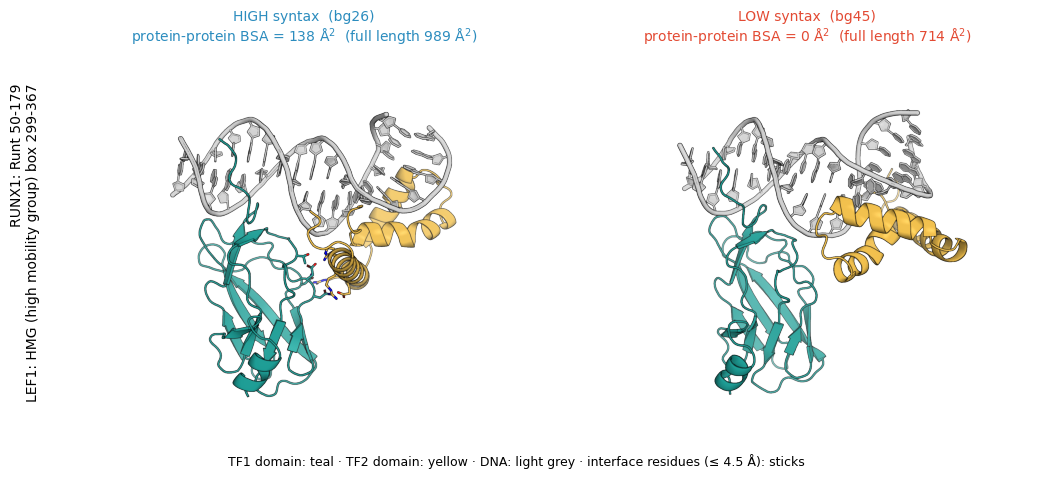

In [6]:
# one panel per TF pair (rows) x class (columns), annotated with the domain-only protein-protein BSA
fig, axes = plt.subplots(len(GROUPS), 2, figsize=(11, 4.6 * len(GROUPS)), squeeze=False)
for row, group in zip(axes, GROUPS):
    tf1, tf2 = group.split("_")[:2]
    for ax, cls in zip(row, ["high", "low"]):
        name = reps[(group, cls)]
        b = bsa.set_index("name").loc[name]
        ax.imshow(mpimg.imread(f"../results/figures/representative_structures/{name}_{TAG}.png"))
        ax.axis("off")
        ax.set_title(f"{cls.upper()} syntax  (bg{name.split('_bg')[1]})\n"
                     f"protein-protein BSA = {b['BSA_domain']:.0f} Å$^2$  (full length {b['BSA']:.0f} Å$^2$)",
                     fontsize=10, color="#2b8cbe" if cls == "high" else "#e34a33")
    row[0].text(-0.04, 0.5, f"{tf1}: {yy_domain_label(tf1)}\n{tf2}: {yy_domain_label(tf2)}",
                transform=row[0].transAxes, ha="right", va="center", fontsize=10, rotation=90)
fig.text(0.5, 0.005, f"TF1 domain: {COL_NAME['TF1']} · TF2 domain: {COL_NAME['TF2']} · DNA: {COL_NAME['DNA']} · "
         + (IDR_NOTE + " · " if IDR_NOTE else "") +
         "interface residues (≤ 4.5 Å): sticks",
         ha="center", fontsize=9)
plt.tight_layout(rect=(0.03, 0.015, 1, 1))
plt.savefig(f"../results/figures/representative_{PAIR}_{TAG}.pdf", bbox_inches='tight')
plt.show()
plt.close()

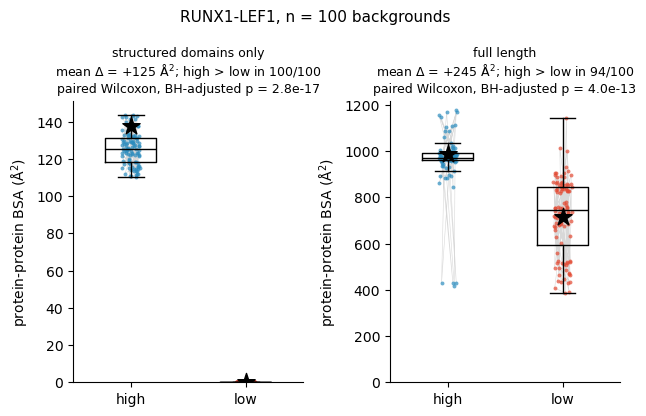

In [7]:
# high vs low protein-protein BSA over all 100 backgrounds: structured domains only and full length.
# grey lines join the two models of the same background; star = the two models shown above.
# statistics: paired Wilcoxon (matched by background), BH-adjusted over the 32 TF pairs of the screen
# (same tests as notebooks 0 and 7, recomputed here from the per-group tables)
from statsmodels.stats.multitest import multipletests
from scipy.stats import wilcoxon
pal = {"high": "#2b8cbe", "low": "#e34a33"}
rng = np.random.default_rng(0)
group = GROUPS[0]
g = bsa[bsa["group"] == group]
fig, axes = plt.subplots(1, 2, figsize=(6.4, 4.2))
for ax, col, table, title in [(axes[0], "BSA_domain", "per_group_paired_domain_bsa_test.csv", "structured domains only"),
                              (axes[1], "BSA", "per_group_paired_bsa_test.csv", "full length")]:
    wide = g.pivot(index="background_idx", columns="class", values=col)
    jit = rng.uniform(-0.08, 0.08, (len(wide), 2))
    ax.plot(np.array([0, 1]) + jit, wide[["high", "low"]].to_numpy(), color="0.7", lw=0.4, alpha=0.5, zorder=1)
    for j, cls in enumerate(["high", "low"]):
        ax.scatter(j + jit[:, j], wide[cls], s=8, alpha=0.7, color=pal[cls], lw=0, zorder=2)
        ax.boxplot(wide[cls], positions=[j], widths=0.45, showfliers=False, medianprops={"color": "black"}, zorder=3)
        ax.scatter(j, g.set_index("name").loc[reps[(group, cls)], col], marker="*", s=170, color="black", zorder=5)
    diff = wide["high"] - wide["low"]
    if col == "BSA_domain" and DOMAIN_OVERRIDE:
        # regions redefined in this notebook: one paired Wilcoxon for this TF pair (no multiple-testing correction)
        p_txt = f"paired Wilcoxon p = {wilcoxon(wide['high'], wide['low'])[1]:.1e}"
        title = "regions shown above"
    else:
        test = pd.read_csv(f"../results/tables/{table}")
        test["q"] = multipletests(test["wilcoxon_p"], method="fdr_bh")[1]
        q = test.set_index("group").loc[group, "q"]
        p_txt = "paired Wilcoxon, BH-adjusted p " + (f"= {q:.1e}" if q > 0 else "< 1e-15")
    ax.set_title(f"{title}\nmean Δ = {diff.mean():+.0f} Å$^2$; high > low in {int((diff > 0).sum())}/{len(diff)}\n"
                 f"{p_txt}", fontsize=9)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["high", "low"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, None)
    ax.set_ylabel("protein-protein BSA (Å$^2$)")
fig.suptitle("-".join(group.split("_")[:2]) + f", n = {len(diff)} backgrounds", fontsize=11)
sns.despine()
plt.tight_layout()
plt.savefig(f"../results/figures/representative_{PAIR}_domain_bsa.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [8]:
# domain-domain interface of the high-syntax representative:
#   footprint = domain residues that lose solvent-accessible area when the two domains meet (>= 1 A^2,
#               Shrake-Rupley, 1.4 A probe, DNA and non-domain residues removed)
parser = MMCIFParser(QUIET=True)

def yy_domain_set(tf):
    d = domains[domains["TF"] == tf]
    return set().union(*(range(s, e + 1) for s, e in zip(d["start"], d["end"])))

def yy_keep(model, keep):
    m = copy.deepcopy(model)
    for ch in list(m):
        if ch.id not in keep:
            m.detach_child(ch.id)
            continue
        for res in list(ch):
            if res.id[1] not in keep[ch.id]:
                ch.detach_child(res.id)
    return m

def yy_res_sasa(model):
    ShrakeRupley(probe_radius=1.4, n_points=100).compute(model, level="R")
    return {(ch.id, r.id[1]): r.sasa for ch in model for r in ch}

def yy_interface(name, tf1, tf2, min_buried=1.0):
    model = parser.get_structure(name, f"{OUT}/{name}_model.cif")[0]
    dom = {"A": yy_domain_set(tf1), "B": yy_domain_set(tf2)}
    alone = {**yy_res_sasa(yy_keep(model, {"A": dom["A"]})), **yy_res_sasa(yy_keep(model, {"B": dom["B"]}))}
    cplx = yy_res_sasa(yy_keep(model, dom))
    return {f"foot_{ch}": sorted(k[1] for k in alone if k[0] == ch and alone[k] - cplx[k] >= min_buried) for ch in "AB"}

group = GROUPS[0]
tf1, tf2 = group.split("_")[:2]
name = reps[(group, "high")]
iface = yy_interface(name, tf1, tf2)
print(f"{name}: footprint {len(iface['foot_A'])} {tf1} residues {iface['foot_A']}, "
      f"{len(iface['foot_B'])} {tf2} residues {iface['foot_B']}")

RUNX1_LEF1_14_157_high_bg26: footprint 7 RUNX1 residues [84, 86, 88, 119, 132, 133, 135], 7 LEF1 residues [342, 346, 349, 350, 353, 356, 360]


In [9]:
# single interface render: both domains and the DNA as cartoon; only the residues in contact
# (the footprint on each domain) are drawn as molecular surface, in their chain colour.
# camera: z from the TF1 footprint towards TF2, y towards the DNA, then rotated about y (side view)
# so the two contact patches are seen edge-on, meeting at the interface
def yy_render_interface_mesh(group, width=1400, height=1300, yaw_deg=90, contact_cut=4.5, carve_cut=3.0, mesh_alpha=0.75):
    """high and low representative in one view: domains + DNA as cartoon, and the TF1 surface that TF2
    lands on as a mesh patch, per model (no mesh where the two domains do not touch).
    low is superposed on high via the TF1 domain, so TF1 and the patch sit in the same place in both panels."""
    tf1, tf2 = group.split("_")[:2]
    p = pymol2.PyMOL()
    p.start()
    cmd = p.cmd
    yy_pymol_colours(cmd)
    for cls in ["high", "low"]:
        cmd.load(f"{OUT}/{reps[(group, cls)]}_model.cif", cls)
    cmd.super(f"low and chain A and resi {yy_resi(tf1)} and name CA", f"high and chain A and resi {yy_resi(tf1)} and name CA")
    cmd.hide("everything")
    yy_pymol_style(cmd)
    cmd.set("mesh_quality", 1)  # coarser grid = fewer mesh lines
    cmd.set("mesh_width", 0.5)
    foot_a = f"resi {'+'.join(map(str, iface['foot_A']))}"
    foot_b = f"resi {'+'.join(map(str, iface['foot_B']))}"
    shown = []
    for cls in ["high", "low"]:
        dom_a, dom_b = f"({cls} and chain A and resi {yy_resi(tf1)})", f"({cls} and chain B and resi {yy_resi(tf2)})"
        cmd.show("cartoon", f"{dom_a} or {dom_b} or ({cls} and chain C+D)")
        cmd.color("yy_TF1", dom_a)
        cmd.color("yy_TF2", dom_b)
        cmd.color("yy_DNA", f"{cls} and chain C+D")
        # mesh = surface of the TF1 residues in contact with TF2 (any heavy atom within contact_cut A), taken from
        # the surface of the TF1 region alone (own object, so TF2/DNA do not shape it) - one continuous sheet,
        # one colour. The mesh is carved to those residues (mesh_carve_*): without carving PyMOL draws it
        # well beyond the selected atoms.
        cmd.create(f"patch_{cls}", dom_a)
        cmd.hide("everything", f"patch_{cls}")
        cmd.select(f"carve_{cls}", f"byres ((patch_{cls} and not elem H) within {contact_cut} of ({dom_b} and not elem H))")
        cmd.show("mesh", f"carve_{cls}")
        cmd.color("yy_IFACE", f"patch_{cls}")
        cmd.set("mesh_carve_selection", f"carve_{cls}", f"patch_{cls}")
        cmd.set("mesh_carve_cutoff", carve_cut, f"patch_{cls}")
        shown.append(f"{dom_a} or {dom_b} or ({cls} and chain C+D) or {yy_show_idr(cmd, cls, tf1, tf2)}")

    # camera from the high model: z = footprint TF1 -> TF2, y toward the DNA, then yaw to a side view
    fa = np.array(cmd.get_coords(f"high and chain A and {foot_a}").mean(0))
    fb = np.array(cmd.get_coords(f"high and chain B and {foot_b}").mean(0))
    dna = np.array(cmd.get_coords("high and chain C+D").mean(0))
    z = (fb - fa) / np.linalg.norm(fb - fa)
    up = dna - fa
    y = up - up.dot(z) * z
    y /= np.linalg.norm(y)
    x = np.cross(y, z)
    w = np.radians(yaw_deg)
    z, x = np.cos(w) * z + np.sin(w) * x, -np.sin(w) * z + np.cos(w) * x
    if CAMERA.startswith("dna"):
        # x = DNA axis of the high model, rotated about that axis (0 deg = TF1 domain pointing up)
        pc = cmd.get_coords("high and chain C+D and name P")
        x = np.linalg.svd(pc - pc.mean(0))[2][0]
        u = cmd.get_coords(f"high and chain A and resi {yy_resi(tf1)}").mean(0) - pc.mean(0)
        u = u - u.dot(x) * x
        u /= np.linalg.norm(u)
        v = np.cross(x, u)
        w = np.radians(float(CAMERA.split(":")[1]))
        z = np.cos(w) * v + np.sin(w) * u
        y = np.cross(z, x)
    view = list(cmd.get_view())
    view[:9] = np.vstack([x, y, z]).T.flatten().tolist()
    cmd.set_view(view)
    cmd.zoom(" or ".join(shown), buffer=1, complete=1)
    for cls in ["high", "low"]:
        cmd.disable("all")
        cmd.enable(cls)
        # the outlined style (ray_trace_mode 1) would trace every mesh line in black, so the mesh is taken
        # from a plain render: outlined scene without mesh + mesh pixels (where plain renders with/without differ)
        png = f"../results/figures/representative_structures/{reps[(group, cls)]}_{TAG}_interface_mesh"
        cmd.png(f"{png}_outlined.png", width=width, height=height, dpi=300, ray=1)
        cmd.set("ray_trace_mode", 0)
        cmd.png(f"{png}_plain.png", width=width, height=height, dpi=300, ray=1)
        cmd.enable(f"patch_{cls}")
        cmd.png(f"{png}_plainmesh.png", width=width, height=height, dpi=300, ray=1)
        cmd.set("ray_trace_mode", 1)
        img, plain, mesh = (mpimg.imread(f"{png}_{k}.png") for k in ["outlined", "plain", "plainmesh"])
        is_mesh = np.abs(mesh - plain).max(axis=2) > 0.02
        # mesh blended over the outlined render (mesh_alpha < 1 lets the cartoon show through)
        base = np.where(img[is_mesh, 3:4] > 0, img[is_mesh, :3], 1.0)
        img[is_mesh, :3] = mesh_alpha * mesh[is_mesh, :3] + (1 - mesh_alpha) * base
        img[is_mesh, 3] = 1.0
        plt.imsave(f"{png}.png", img)
        for k in ["outlined", "plain", "plainmesh"]:
            os.remove(f"{png}_{k}.png")
    p.stop()

yy_render_interface_mesh(group)

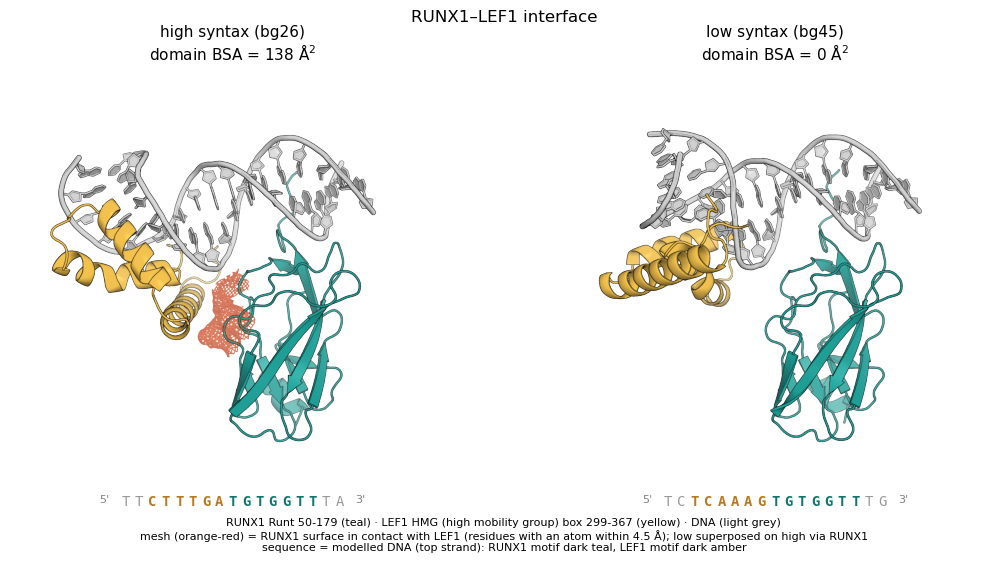

In [10]:
# figure: interface patch (mesh) in the high- and low-syntax representatives
dom_bsa = bsa.set_index("name")["BSA_domain"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, cls in zip(axes, ["high", "low"]):
    rep = reps[(group, cls)]
    ax.imshow(mpimg.imread(f"../results/figures/representative_structures/{rep}_{TAG}_interface_mesh.png"))
    ax.axis("off")
    ax.set_title(f"{cls} syntax (bg{rep.split('_bg')[1]})\ndomain BSA = {dom_bsa[rep]:.0f} Å$^2$", fontsize=11)
    yy_draw_sequence(ax, rep)
fig.suptitle(f"{tf1}–{tf2} interface", fontsize=12)
fig.text(0.5, 0.01,
         f"{tf1} {yy_domain_label(tf1)} ({COL_NAME['TF1']}) · {tf2} {yy_domain_label(tf2)} ({COL_NAME['TF2']}) · "
         f"DNA ({COL_NAME['DNA']})"
         + (" · " + IDR_NOTE if IDR_NOTE else "") +
         f"\nmesh ({COL_NAME['IFACE']}) = {tf1} surface in contact with {tf2} (residues with an atom within 4.5 Å); "
         f"low superposed on high via {tf1}\n"
         f"sequence = modelled DNA (top strand): {tf1} motif {COL_NAME['MOTIF1']}, {tf2} motif {COL_NAME['MOTIF2']}",
         ha="center", va="bottom", fontsize=8)
plt.tight_layout(rect=(0, 0.11, 1, 0.97))
plt.savefig(f"../results/figures/representative_{tf1}_{tf2}_{TAG}_interface.pdf", bbox_inches='tight')
plt.show()
plt.close()

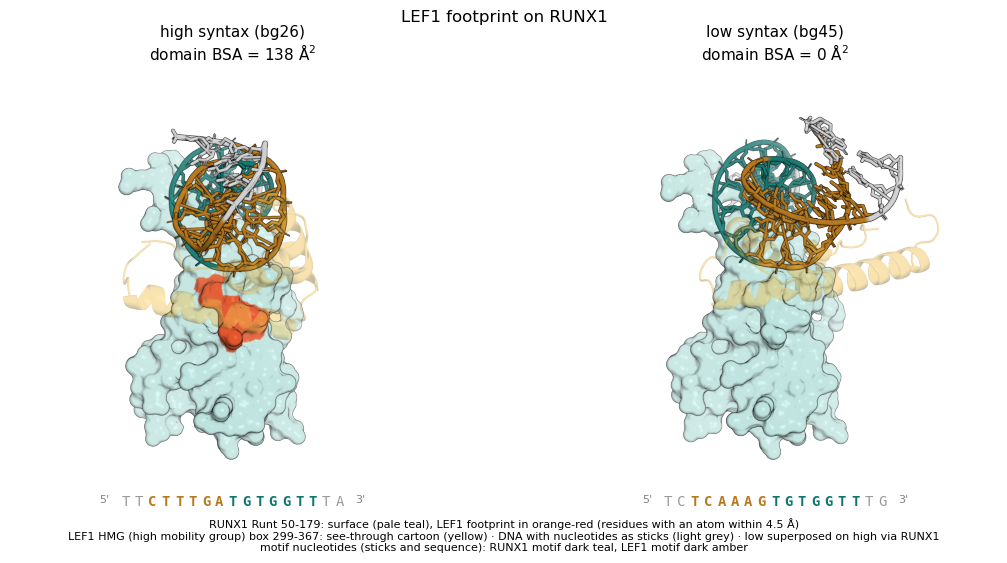

In [11]:
# "binder footprint" view: TF1 as a surface with the TF2 footprint painted on it, TF2 as a see-through cartoon,
# DNA with its nucleotides as sticks. Footprint = TF1 residues with a heavy atom within contact_cut A of TF2,
# per model; low is superposed on high via TF1, so both panels share one view.
# Camera: as the mesh figure if CAMERA = "dna:<deg>", otherwise face-on to the footprint from the TF2 side.
def yy_render_footprint(group, width=1400, height=1300, contact_cut=4.5, tf2_transparency=0.55):
    tf1, tf2 = group.split("_")[:2]
    p = pymol2.PyMOL()
    p.start()
    cmd = p.cmd
    yy_pymol_colours(cmd)
    cmd.set_color("yy_TF1_surf", [0.74, 0.89, 0.87])  # pale teal: TF1 surface outside the footprint
    for cls in ["high", "low"]:
        cmd.load(f"{OUT}/{reps[(group, cls)]}_model.cif", cls)
    cmd.super(f"low and chain A and resi {yy_resi(tf1)} and name CA", f"high and chain A and resi {yy_resi(tf1)} and name CA")
    cmd.hide("everything")
    yy_pymol_style(cmd)
    cmd.set("surface_quality", 2)
    cmd.set("cartoon_ring_mode", 0)
    cmd.set("stick_radius", 0.3)
    shown = []
    for cls in ["high", "low"]:
        dom_a, dom_b = f"({cls} and chain A and resi {yy_resi(tf1)})", f"({cls} and chain B and resi {yy_resi(tf2)})"
        cmd.show("cartoon", f"{cls} and chain C+D")
        cmd.show("sticks", f"{cls} and chain C+D and not elem H")  # nucleotides
        cmd.color("yy_DNA", f"{cls} and chain C+D")
        yy_colour_motifs(cmd, cls, reps[(group, cls)])
        # TF1 surface from its own object (TF2/DNA do not shape it); footprint residues in the interface colour
        cmd.create(f"surf_{cls}", dom_a)
        cmd.show_as("surface", f"surf_{cls}")
        cmd.color("yy_TF1_surf", f"surf_{cls}")
        cmd.color("yy_IFACE", f"byres ((surf_{cls} and not elem H) within {contact_cut} of ({dom_b} and not elem H))")
        # TF2 as its own object so that only it is see-through
        cmd.create(f"tf2_{cls}", dom_b)
        cmd.show_as("cartoon", f"tf2_{cls}")
        cmd.color("yy_TF2", f"tf2_{cls}")
        cmd.set("cartoon_transparency", tf2_transparency, f"tf2_{cls}")
        shown.append(f"{dom_a} or {dom_b} or ({cls} and chain C+D)")

    # camera on the TF2 side of the high model, looking straight at the footprint; DNA toward the top
    fa = np.array(cmd.get_coords(f"high and chain A and resi {'+'.join(map(str, iface['foot_A']))}").mean(0))
    fb = np.array(cmd.get_coords(f"high and chain B and resi {'+'.join(map(str, iface['foot_B']))}").mean(0))
    dna = np.array(cmd.get_coords("high and chain C+D").mean(0))
    z = (fb - fa) / np.linalg.norm(fb - fa)
    up = dna - fa
    y = up - up.dot(z) * z
    y /= np.linalg.norm(y)
    x = np.cross(y, z)
    if CAMERA.startswith("dna"):
        pc = cmd.get_coords("high and chain C+D and name P")
        x = np.linalg.svd(pc - pc.mean(0))[2][0]
        u = cmd.get_coords(f"high and chain A and resi {yy_resi(tf1)}").mean(0) - pc.mean(0)
        u = u - u.dot(x) * x
        u /= np.linalg.norm(u)
        w = np.radians(float(CAMERA.split(":")[1]))
        z = np.cos(w) * np.cross(x, u) + np.sin(w) * u
        y = np.cross(z, x)
    view = list(cmd.get_view())
    view[:9] = np.vstack([x, y, z]).T.flatten().tolist()
    cmd.set_view(view)
    cmd.zoom(" or ".join(shown), buffer=1, complete=1)
    for cls in ["high", "low"]:
        cmd.disable("all")
        for obj in [cls, f"surf_{cls}", f"tf2_{cls}"]:
            cmd.enable(obj)
        cmd.png(f"../results/figures/representative_structures/{reps[(group, cls)]}_{TAG}_footprint.png",
                width=width, height=height, dpi=300, ray=1)
    p.stop()

yy_render_footprint(group)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
for ax, cls in zip(axes, ["high", "low"]):
    rep = reps[(group, cls)]
    ax.imshow(mpimg.imread(f"../results/figures/representative_structures/{rep}_{TAG}_footprint.png"))
    ax.axis("off")
    ax.set_title(f"{cls} syntax (bg{rep.split('_bg')[1]})\ndomain BSA = {dom_bsa[rep]:.0f} Å$^2$", fontsize=11)
    yy_draw_sequence(ax, rep)
fig.suptitle(f"{tf2} footprint on {tf1}", fontsize=12)
fig.text(0.5, 0.01,
         f"{tf1} {yy_domain_label(tf1)}: surface (pale teal), {tf2} footprint in {COL_NAME['IFACE']} "
         f"(residues with an atom within 4.5 Å)\n{tf2} {yy_domain_label(tf2)}: see-through cartoon ({COL_NAME['TF2']}) · "
         f"DNA with nucleotides as sticks ({COL_NAME['DNA']}) · low superposed on high via {tf1}\n"
         f"motif nucleotides (sticks and sequence): {tf1} motif {COL_NAME['MOTIF1']}, {tf2} motif {COL_NAME['MOTIF2']}",
         ha="center", va="bottom", fontsize=8)
plt.tight_layout(rect=(0, 0.11, 1, 0.97))
plt.savefig(f"../results/figures/representative_{tf1}_{tf2}_{TAG}_footprint.pdf", bbox_inches='tight')
plt.show()
plt.close()